Clase 012 · `012_concatenar` · La versión limpia de la libreta anterior: sin pasos de
exploración, sólo las líneas que hacen falta para consolidar los diez archivos de ESOLMET en un
DataFrame y mirarlo con `plot(subplots=True)`. Es el patrón que la clase 014 convierte en
función.

::: {.callout-important title="Datos"}
Los diez archivos `ClimaLab_*.csv` de `ejercicio_01_columnas/` (uno por variable) no viajan en
el repositorio; colócalos en `clases/012_concatenar/data/001_raw/ejercicio_01_columnas/` (se
comparten en clase). La carpeta `ejercicio_02_fechas/`, con un archivo por día, se usa en la
clase 014.
:::

## Librerías

`pandas` y `glob`. Esta vez no hace falta importar `matplotlib`: `DataFrame.plot` lo llama por
dentro.

In [1]:
import pandas as pd
import glob as glob

## Listar, leer y concatenar en dos líneas

`glob` lista los archivos y la comprensión de lista los lee; `concat(axis=1, sort=True)` los
pega como columnas. `sort=True` ordena el índice de tiempo del resultado, para que no dependa
del orden en que `glob` devolvió los archivos ni de cómo venga cada uno. Mismo resultado que en
la libreta anterior: 172 433 filas y diez columnas, con `p_atm` en `NaN` donde su archivo aún
no tenía registros.

In [4]:
archivos = glob.glob("../data/001_raw/ejercicio_01_columnas/*")
esolmet = pd.concat([pd.read_csv(archivo,index_col=0,parse_dates=True) for archivo in archivos],axis=1,sort=True)
esolmet

,dhi,dni,ghi,p_atm,rain_acc,rh,tdb,uv,wd,ws
date,,,,,,,,,,
2026-04-08 00:00:00,0.00,0.00,0.0,NaN,0.0,54.05,23.56,0.000,4.604,1.088
2026-04-08 00:01:00,0.00,0.00,0.0,NaN,0.0,54.20,23.53,0.000,347.200,1.162
2026-04-08 00:02:00,0.00,0.00,0.0,NaN,0.0,54.41,23.49,0.000,0.157,1.125
2026-04-08 00:03:00,0.00,0.00,0.0,NaN,0.0,54.29,23.48,0.000,347.800,1.100
2026-04-08 00:04:00,0.00,0.00,0.0,NaN,0.0,54.57,23.44,0.000,347.900,1.088
...,...,...,...,...,...,...,...,...,...,...
2026-08-05 18:00:00,80.60,99.40,134.4,860.0803,0.0,36.90,31.67,0.007,122.100,0.938
2026-08-05 18:01:00,76.32,103.90,129.3,860.0957,0.0,37.13,31.65,0.006,68.510,1.275
2026-08-05 18:02:00,71.56,97.50,120.0,860.1653,0.0,37.18,31.63,0.006,113.400,1.012


## Todas las variables de un vistazo

`esolmet.plot(subplots=True)` dibuja un panel por columna con el tiempo en el eje horizontal; el
`;` evita que Jupyter imprima la lista de `Axes`. Es la revisión mínima del consolidado:
`p_atm` cambia de comportamiento a mediados de mayo (antes oscila mucho, después queda casi
plana cerca de 860), `rain_acc` es casi todo ceros con lluvias puntuales, y `wd` se ve como un
bloque sólido porque la dirección del viento salta entre 0 y 360 grados a cada minuto.

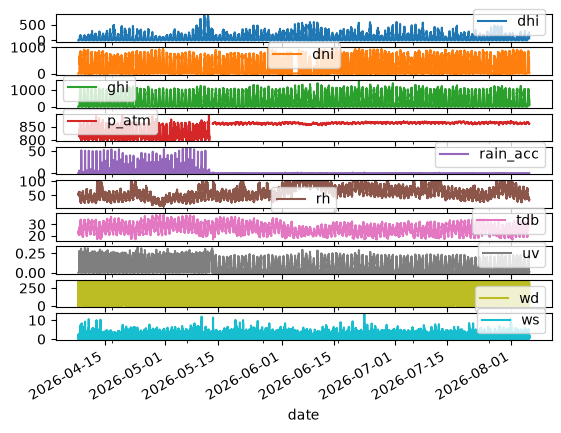

In [5]:
#| label: fig-concat-subplots
#| fig-cap: "Las diez variables de ESOLMET consolidadas a partir de diez archivos, de abril a agosto de 2026, un panel por columna. `p_atm` cambia de comportamiento a mediados de mayo y `wd` llena su panel como un bloque."
#| fig-alt: "Diez paneles apilados con leyenda; las irradiancias forman picos diarios, la presión es ruidosa hasta mediados de mayo y luego plana, la dirección de viento llena todo su panel."
esolmet.plot(subplots=True);